# Noise

PyWake contains a simple noise-progagation model, `ISONoise`, which models the sound-pressure level from a number of sound sources (wind turbines) at a number of receivers taking into account:

- Spherical geometrical spreading (DSF/ISO/DIS 9613-2)
- Ground reflection/absorption (DSF/ISO/DIS 9613-2)
- Atmospheric absorption (DS/ISO 9613-1:1993)


The model is based on the iso standards:

```
DSF/ISO/DIS 9613-2
Acoustics – Attenuation of sound during propagation – Part 2:
Engineering method for the prediction of sound pressure levels outdoors
```

and

```
DS/ISO 9613-1:1993
Akustik. Måling og beskrivelse af ekstern støj. Lydudbredelsesdæmpning udendørs. Del 1:
Metode til beregning af luftabsorption
```

The implementation and interface is preliminary and may be subject to changes

In [51]:
# Install PyWake if needed
try:
    import py_wake
except ModuleNotFoundError:
    !pip install git+https://gitlab.windenergy.dtu.dk/TOPFARM/PyWake.git

In [52]:
import matplotlib.pyplot as plt
import numpy as np

from py_wake.noise_models.iso import ISONoiseModel

from py_wake.deficit_models.gaussian import ZongGaussian
from py_wake.flow_map import XYGrid
from py_wake.turbulence_models.crespo import CrespoHernandez
from py_wake.site._site import UniformSite
from py_wake.examples.data.swt_dd_142_4100_noise.swt_dd_142_4100 import SWT_DD_142_4100
from py_wake.utils.layouts import rectangle
from py_wake.utils.plotting import setup_plot

## Sound source

To model the emitted sound from the wind turbine sources, the `WindTurbine` object must contain a `sound_power_level`-function.

An example wind turbine, `SWT_DD_142_4100`, is implemented in `py_wake.examples.data.swt_dd_142_4100_noise.swt_dd_142_4100` based on power, ct and noise data from the wind turbine catalogue in [WindPro](https://www.emd-international.com/software/) (demo version).

This wind turbine are able to operate at 7 different modes with reduced power and noise.

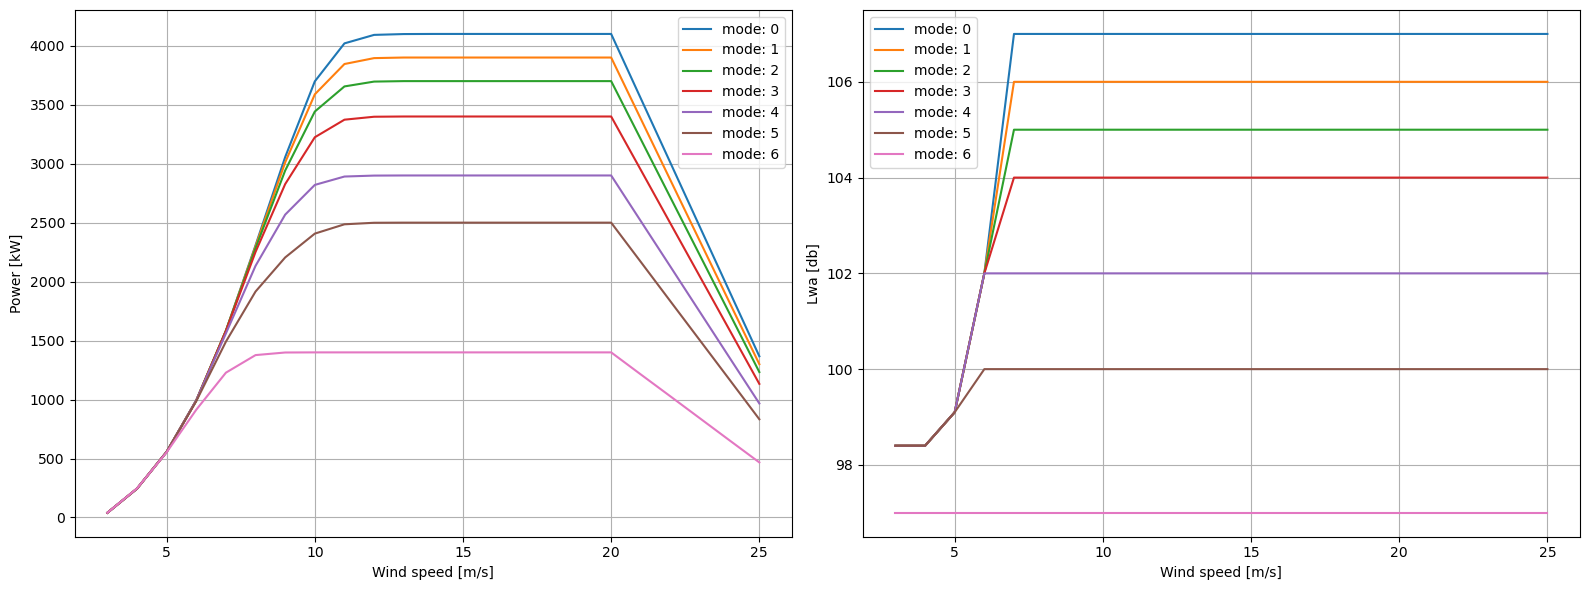

In [53]:
wt = SWT_DD_142_4100()

ax1,ax2 = plt.subplots(1,2,figsize=(16,6))[1]
ws = np.arange(3, 26)
for m in range(7):
    ax1.plot(ws, wt.power(ws, mode=m) / 1000, label=f'mode: {m}')
    ax2.plot(ws, wt.ds.LwaRef.sel(mode=m, ws=ws), label=f'mode: {m}')

setup_plot(ax=ax1, xlabel='Wind speed [m/s]', ylabel='Power [kW]')
setup_plot(ax=ax2, xlabel='Wind speed [m/s]', ylabel='Lwa [db]')

Furthermore, the sound-power level is available as a function of mode, wind speed and frequency  

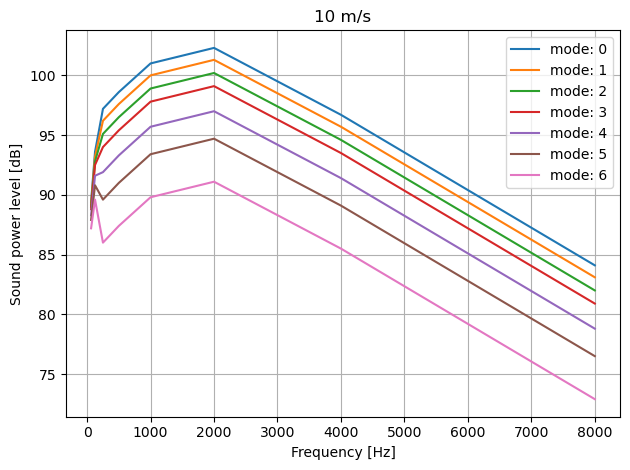

In [54]:
for m in range(7):
    freq, sound_power = wt.sound_power_level(ws=10, mode=m)
    plt.plot(freq, sound_power[0], label=f'mode: {m}')
setup_plot(xlabel='Frequency [Hz]', ylabel='Sound power level [dB]', title="10 m/s")

## Noise at receivers
To model the noise at specific receiver positions, we first need to setup a `WindFarmModel´ and run a simulation

In [55]:
wt = SWT_DD_142_4100()
wfm = ZongGaussian(UniformSite(), wt, turbulenceModel=CrespoHernandez())
x, y = rectangle(5, 5, 5 * wt.diameter())
wd, ws = 270, 8
sim_res = wfm(x, y, wd=wd, ws=ws, mode=[0,0,6,0,0])

/home/frederikwr/Documents/git/PyWake/py_wake/deficit_models/gaussian.py:405: UserWarning: The ZongGaussian model is not representative of the setup used in the literature. For this, use py_wake.literature.gaussian_models.Zong_PorteAgel_2020 instead
  DeprecatedModel.__init__(self, 'py_wake.literature.gaussian_models.Zong_PorteAgel_2020')


In this case the wind farm consist of 5 wind turbines in a row aligned with the wind. 
Wind turbines, 0,1 and 3,4 operate in mode 0 while wind turbin 2 is running in the most derated and silent mode. 

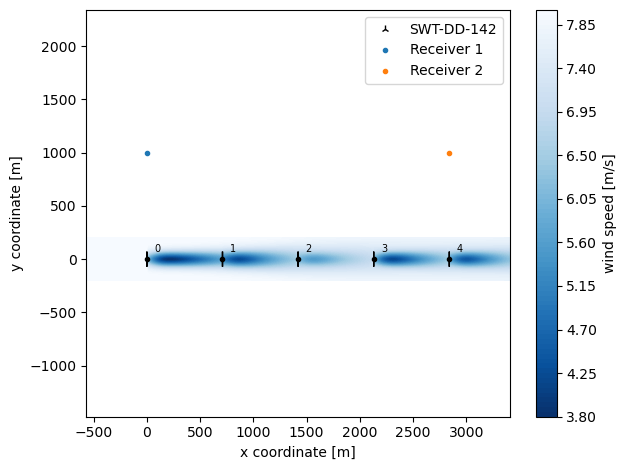

In [56]:
sim_res.flow_map().plot_wake_map()
plt.plot([x[0]], [1000], '.', label='Receiver 1')
plt.plot([x[-1]], [1000], '.', label='Receiver 2')
setup_plot(grid=False, xlabel='x coordinate [m]', ylabel='y coordinate [m]')

We can no model the sound pressure level at the two recievers. In this case the upstream wind turbines operates at higher wind speed than the down wind turbines, and therefore a higher sound pressure level will be reveived at receiver 1. 

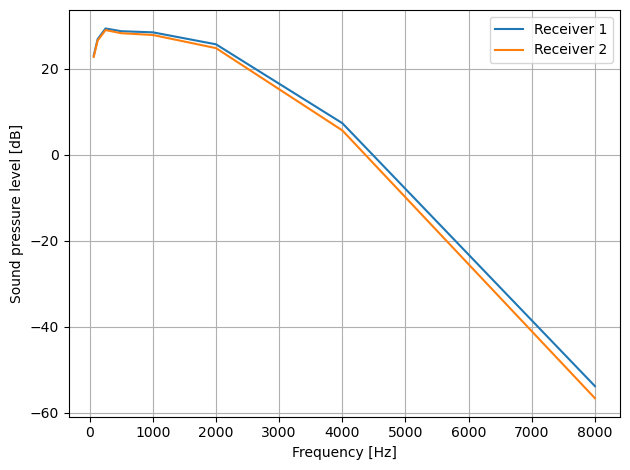

In [57]:
nm = sim_res.noise_model()
total_sp_jlk, spl_jlkf = nm(rec_x=[x[0], x[-1]], rec_y=[1000, 1000], rec_h=2, patm=101325, Temp=20, RHum=80, ground_type=0.0)
plt.plot(nm.freqs, spl_jlkf[0, 0, 0], label='Receiver 1')
plt.plot(nm.freqs, spl_jlkf[1, 0, 0], label='Receiver 2')
setup_plot(xlabel='Frequency [Hz]', ylabel='Sound pressure level [dB]')

Finally, a sound map can be generated

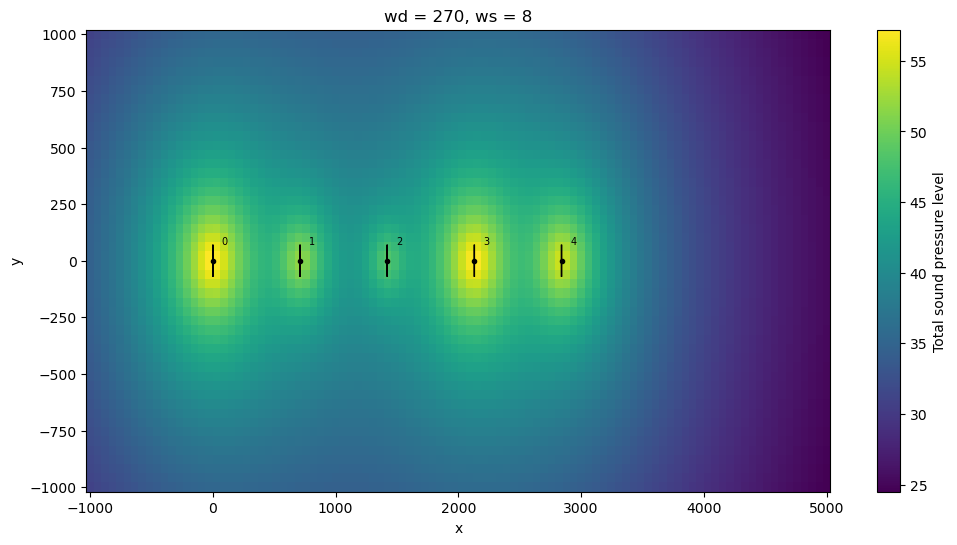

In [58]:
plt.figure(figsize=(12,6))
nmap = sim_res.noise_map(grid=XYGrid(x=np.linspace(-1000, 5000, 100), y=np.linspace(-1000, 1000, 50), h=2))
nmap['Total sound pressure level'].squeeze().plot()
wt.plot(x, y, wd=wd)

## Directional Sound Correction
PyWake's noise model supports directional corrections automatically when using wind turbines that include directional sound power level data. The `TurbineNoise` class from the noise example includes a `spherical_interpolate_delta_swl` method that interpolates directional corrections based on spherical coordinates.

### Using Built-in Directional Corrections
Here's how to use the directional correction functionality with the existing TurbineNoise turbine:

/home/frederikwr/Documents/git/PyWake/py_wake/deficit_models/gaussian.py:405: UserWarning: The ZongGaussian model is not representative of the setup used in the literature. For this, use py_wake.literature.gaussian_models.Zong_PorteAgel_2020 instead
  DeprecatedModel.__init__(self, 'py_wake.literature.gaussian_models.Zong_PorteAgel_2020')


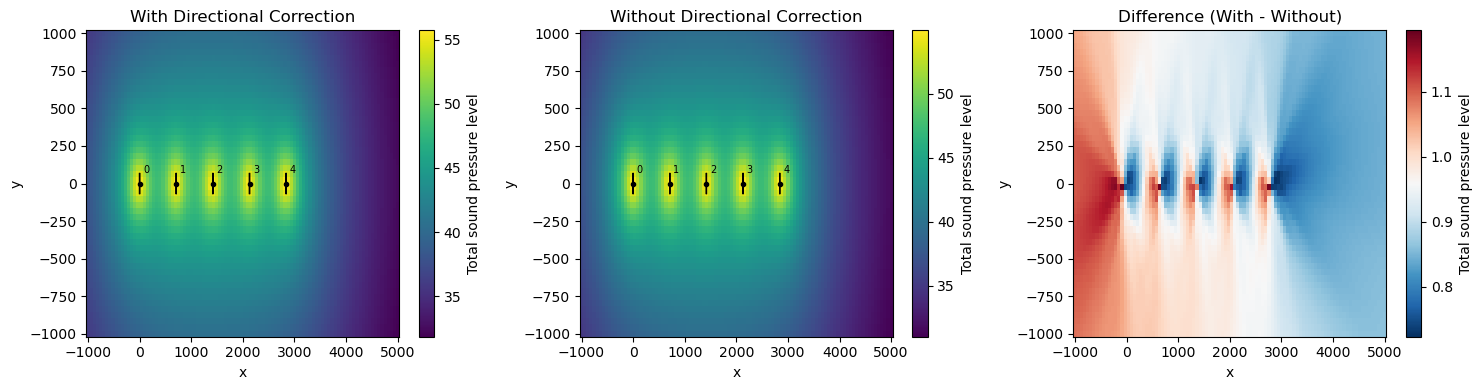

In [59]:
from py_wake.examples.data.noise_example.turbine_noise import TurbineNoise

wt = TurbineNoise()
wfm = ZongGaussian(UniformSite(), wt, turbulenceModel=CrespoHernandez())
x, y = rectangle(5, 5, 5 * wt.diameter())

sim_res = wfm(x, y, wd=wd, ws=ws, mode=5)

grid = XYGrid(x=np.linspace(-1000, 5000, 100), y=np.linspace(-1000, 1000, 50), h=[2])

nmap_with = sim_res.noise_map(grid=grid)

# Create custom noise model class without directional correction
class ISONoiseModelNoCorrection(ISONoiseModel):
    def __init__(self, *args, **kwargs):
        # Force delta_swl_correction to None
        kwargs['delta_swl_correction'] = None
        super().__init__(*args, **kwargs)

nmap_without = sim_res.noise_map(grid=grid, noiseModel=ISONoiseModelNoCorrection)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

nmap_with['Total sound pressure level'].squeeze().plot(ax=axes[0], cmap='viridis')
axes[0].set_title('With Directional Correction')
wt.plot(x, y, wd=wd, ax=axes[0])

nmap_without['Total sound pressure level'].squeeze().plot(ax=axes[1], cmap='viridis')
axes[1].set_title('Without Directional Correction')
wt.plot(x, y, wd=wd, ax=axes[1])

diff = nmap_with['Total sound pressure level'].squeeze() - nmap_without['Total sound pressure level'].squeeze()
diff.plot(ax=axes[2], cmap='RdBu_r')
axes[2].set_title('Difference (With - Without)')

plt.tight_layout()
plt.show()

### Yaw Effects on Directional Sound
Turbine yaw also influences directional sound patterns. When turbines are yawed relative to the wind direction, the directional corrections are automatically adjusted to account for the changed rotor orientation.

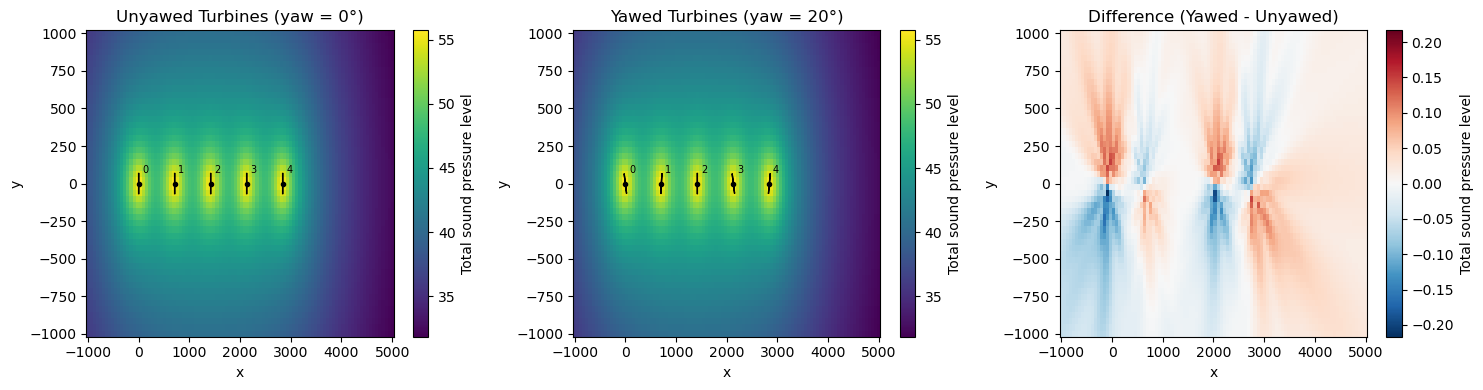

In [60]:
sim_res_unyawed = wfm(x, y, wd=wd, ws=ws, mode=5, yaw=0)
sim_res_yawed = wfm(x, y, wd=wd, ws=ws, mode=5, yaw=[20, -10, 0, 20, -15])

nmap_unyawed = sim_res_unyawed.noise_map(grid=grid)
nmap_yawed = sim_res_yawed.noise_map(grid=grid)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
nmap_unyawed['Total sound pressure level'].squeeze().plot(ax=axes[0], cmap='viridis')
axes[0].set_title('Unyawed Turbines (yaw = 0°)')
wt.plot(x, y, wd=wd, yaw=[0], ax=axes[0])

nmap_yawed['Total sound pressure level'].squeeze().plot(ax=axes[1], cmap='viridis')
axes[1].set_title('Yawed Turbines (yaw = 20°)')
wt.plot(x, y, wd=wd, yaw=[20, -10, 0, 20, -15], ax=axes[1])

diff = nmap_yawed['Total sound pressure level'].squeeze() - nmap_unyawed['Total sound pressure level'].squeeze()
diff.plot(ax=axes[2], cmap='RdBu_r')
axes[2].set_title('Difference (Yawed - Unyawed)')

plt.tight_layout()
plt.show()
